# DR1 MetaCal catalogue: HEALPix maps

Maps of the Euclid DR1 MetaCal shear catalogue (`dr1_dps_tiles_v6/metacal_only`, B-Mode Tiger Team release; see
`data/README_v6.md`). The archive holds one Parquet file per tile. We read only the columns we need from each
tile and add them into HEALPix maps, then save the maps so the plots can be remade without re-reading the
catalogue.

⚠︎ These data are unblinded and restricted to the B-Mode Tiger Team.

In [1]:
import glob
import json
import os

import healpy as hp
import matplotlib.pyplot as plt
import numpy as np
import pyarrow.parquet as pq

dr1_dir = os.path.abspath(os.getcwd())
data_dir = f'{dr1_dir}/data'
tile_dir = f'{data_dir}/metacal_only'
fig_dir = f'{dr1_dir}/figures/metacal/maps'
os.makedirs(fig_dir, exist_ok=True)

nside = 512   # ~6.9 arcmin pixels for display
nside_qml = 64

tiles = sorted(glob.glob(f'{tile_dir}/tile_*.parquet'))
print(len(tiles), 'tiles')

8301 tiles


## Accumulate maps

For each pixel we store the galaxy count, $\sum w$, $\sum w^2$, $\sum w e_1$, $\sum w e_2$ and
$\sum w (e_1^2 + e_2^2)$, using the calibrated weight `SHE_METACAL_WEIGHT_CORRECTED` and the calibrated
ellipticities `SHE_METACAL_E{1,2}_CORRECTED`. Only galaxies with an assigned tomographic bin (`TOM_BIN_ID` ≥ 1)
are kept, as in the TR1 South analysis.

In [2]:
maps_path = f'{data_dir}/metacal/metacal_maps_N{nside}.npz'
cols = ['SHE_METACAL_RA', 'SHE_METACAL_DEC', 'SHE_METACAL_E1_CORRECTED', 'SHE_METACAL_E2_CORRECTED',
        'SHE_METACAL_WEIGHT_CORRECTED', 'TOM_BIN_ID']

if os.path.exists(maps_path):
    maps = dict(np.load(maps_path))
else:
    npix = hp.nside2npix(nside)
    names = ['n', 'sw', 'sw2', 'swe1', 'swe2', 'swee']
    maps = {k: np.zeros(npix) for k in names}
    n_bin = np.zeros(7, dtype=np.int64)
    for i, f in enumerate(tiles):
        t = pq.read_table(f, columns=cols).to_pandas()
        t = t[t['TOM_BIN_ID'] >= 1]
        pix = hp.ang2pix(nside, t['SHE_METACAL_RA'].values, t['SHE_METACAL_DEC'].values, lonlat=True)
        w = t['SHE_METACAL_WEIGHT_CORRECTED'].values.astype(np.float64)
        e1 = t['SHE_METACAL_E1_CORRECTED'].values
        e2 = t['SHE_METACAL_E2_CORRECTED'].values
        for k, v in zip(names, [None, w, w ** 2, w * e1, w * e2, w * (e1 ** 2 + e2 ** 2)]):
            maps[k] += np.bincount(pix, weights=v, minlength=npix)
        n_bin += np.bincount(t['TOM_BIN_ID'].values, minlength=7)[:7]
        if i % 1000 == 0:
            print(i, f)
    maps['n_bin'] = n_bin
    np.savez(maps_path, **maps)

n_gal = maps['n'].sum()
print(f'{n_gal:.4g} galaxies')
print('per tomographic bin:', dict(zip(range(1, 7), maps['n_bin'][1:])))

1.267e+08 galaxies
per tomographic bin: {1: np.int64(24849033), 2: np.int64(21767316), 3: np.int64(21443636), 4: np.int64(19856311), 5: np.int64(19199302), 6: np.int64(19616221)}


## South and North fields

DR1 has two separate fields, calibrated in separate shear runs (`DR1_TT_TEST_SOUTH_R2` and
`DR1_TT_TEST_NORTH_R2_2`) and with different ground-based photometry, so we analyse them separately. The
catalogue has no field column, but the fields are far apart on the sky: South spans Dec −70° to −10° and North
Dec +50° to +80°, with nothing in between. So the split is simply the sign of the declination.

In [3]:
pix_area_arcmin2 = hp.nside2pixarea(nside, degrees=True) * 3600
occupied = maps['n'] > 0
_, dec_pix = hp.pix2ang(nside, np.arange(hp.nside2npix(nside)), lonlat=True)
fields = {'South': occupied & (dec_pix < 0), 'North': occupied & (dec_pix >= 0)}

## Summary numbers

Area is the area of pixels holding at least one galaxy, so at this resolution it slightly overestimates the
true footprint at survey edges and holes. $\sigma_\epsilon$ is the weighted per-component shape scatter, and
$n_{\rm eff} = (\sum w)^2/\sum w^2$ per arcmin² (as in `TR1/report_south/TR1Southexplainer.md`).

In [4]:
for name, sel in fields.items():
    area_deg2 = sel.sum() * pix_area_arcmin2 / 3600
    sigma_e = np.sqrt(maps['swee'][sel].sum() / (2 * maps['sw'][sel].sum()))
    n_eff = maps['sw'][sel].sum() ** 2 / maps['sw2'][sel].sum() / (area_deg2 * 3600)
    print(f'{name}: {maps["n"][sel].sum():.4g} galaxies, area {area_deg2:.0f} deg^2 (f_sky = {sel.mean():.4f}), '
          f'raw density {maps["n"][sel].sum() / (area_deg2 * 3600):.1f} /arcmin^2, n_eff {n_eff:.1f} /arcmin^2, '
          f'sigma_e {sigma_e:.3f}')

South: 9.892e+07 galaxies, area 1481 deg^2 (f_sky = 0.0359), raw density 18.6 /arcmin^2, n_eff 18.5 /arcmin^2, sigma_e 0.280
North: 2.781e+07 galaxies, area 454 deg^2 (f_sky = 0.0110), raw density 17.0 /arcmin^2, n_eff 17.0 /arcmin^2, sigma_e 0.279


## Galaxy density

Raw galaxy number density per arcmin². Grey is outside the footprint.

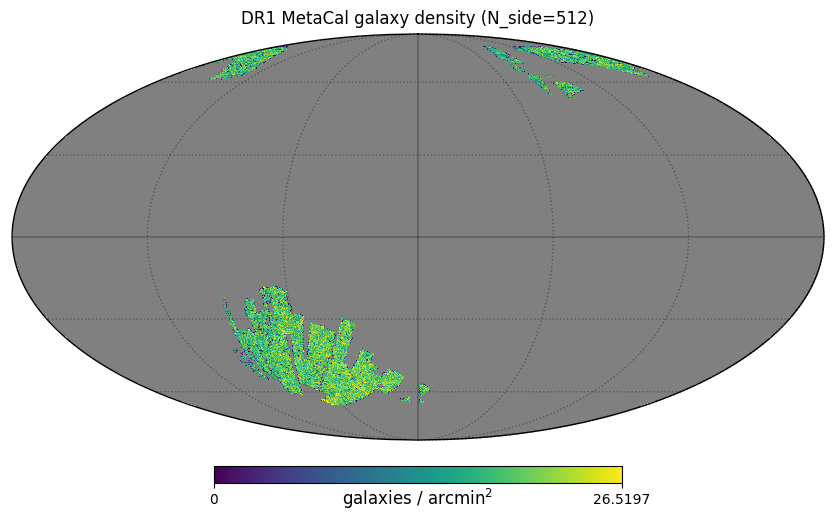

In [5]:
dens = np.where(occupied, maps['n'] / pix_area_arcmin2, hp.UNSEEN)
vmax = np.percentile(dens[occupied], 99)
hp.mollview(dens, title=f'DR1 MetaCal galaxy density (N_side={nside})', unit='galaxies / arcmin$^2$',
            min=0, max=vmax, cmap='viridis')
hp.graticule(dpar=30, dmer=60, alpha=0.3)
plt.savefig(f'{fig_dir}/metacal_density_mollview.png', dpi=150, bbox_inches='tight')
plt.show()

The footprint is small on the full sky, so each field is also shown on its own in an orthographic view
centred on it.

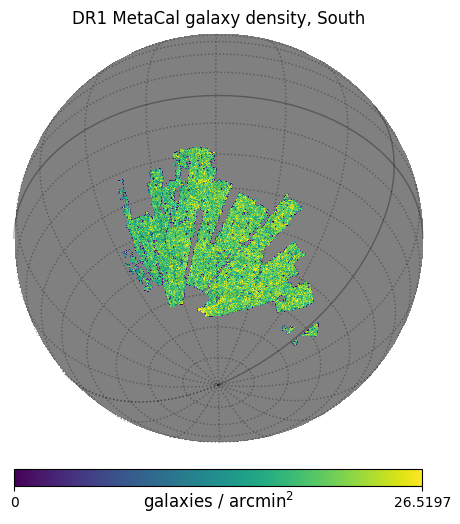

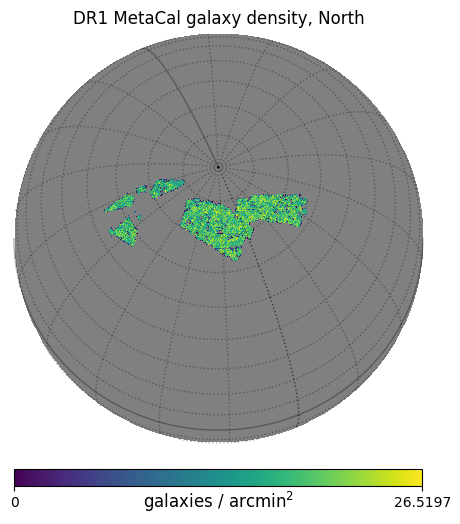

In [6]:
def field_view(m, sel, nside_m, **kw):
    # Orthographic half-sky view centred on the field (circular mean of RA, so fields crossing RA = 0 work)
    ra_s, dec_s = hp.pix2ang(nside_m, np.where(sel)[0], lonlat=True)
    ra_mid = np.degrees(np.arctan2(np.sin(np.radians(ra_s)).mean(), np.cos(np.radians(ra_s)).mean())) % 360
    hp.orthview(m, rot=(ra_mid, dec_s.mean()), half_sky=True, **kw)
    hp.graticule(dpar=10, dmer=20, alpha=0.3)


for name, sel in fields.items():
    field_view(np.where(sel, dens, hp.UNSEEN), sel, nside, min=0, max=vmax, cmap='viridis',
               unit='galaxies / arcmin$^2$', title=f'DR1 MetaCal galaxy density, {name}')
    plt.savefig(f'{fig_dir}/metacal_density_{name.lower()}.png', dpi=150, bbox_inches='tight')
    plt.show()

## At the QML resolution, N_side = 64

Effective galaxy number per pixel and the per-pixel noise relative to the median. This is what QML would see:
pixels at the edges hold fewer galaxies, so their noise is higher than the single `noise_var` QML assumes. In
TR1 South we removed pixels less than 50% covered for this reason.

South: 2132 N64 pixels with galaxies (f_sky = 0.0434); noise ratio percentiles (50/90/99): [  1.     5.14 436.62]


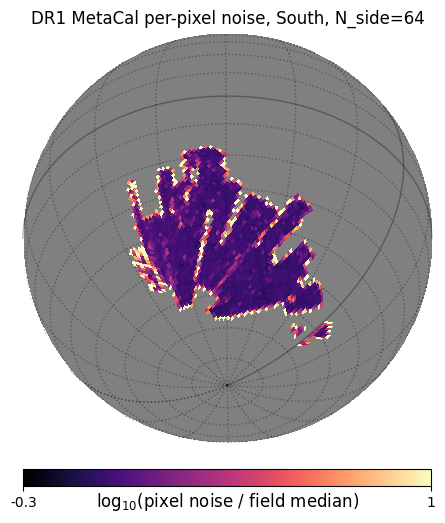

North: 711 N64 pixels with galaxies (f_sky = 0.0145); noise ratio percentiles (50/90/99): [1.00000e+00 1.07400e+01 2.69247e+03]


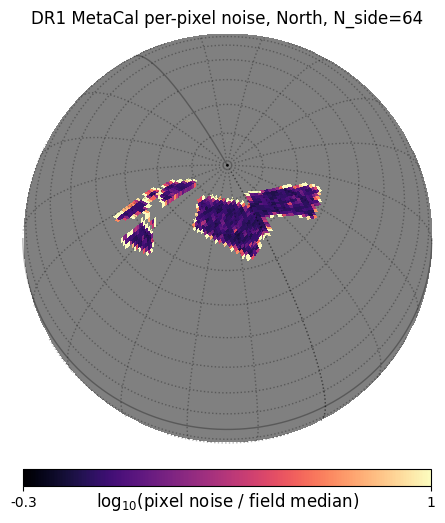

In [7]:
# ud_grade with power=-2 sums the fine pixels, so these are per-N64-pixel sums
sw64 = hp.ud_grade(maps['sw'], nside_qml, power=-2)
sw2_64 = hp.ud_grade(maps['sw2'], nside_qml, power=-2)
neff64 = np.where(sw2_64 > 0, sw64 ** 2 / np.where(sw2_64 > 0, sw2_64, 1), 0)
_, dec64 = hp.pix2ang(nside_qml, np.arange(hp.nside2npix(nside_qml)), lonlat=True)
fields64 = {'South': (neff64 > 0) & (dec64 < 0), 'North': (neff64 > 0) & (dec64 >= 0)}

for name, sel in fields64.items():
    # Noise relative to the field's own median: each field gets its own noise level in QML
    noise_ratio = np.where(sel, np.median(neff64[sel]) / np.where(sel, neff64, 1), 1.0)
    print(f'{name}: {sel.sum()} N64 pixels with galaxies (f_sky = {sel.mean():.4f}); '
          f'noise ratio percentiles (50/90/99): {np.percentile(noise_ratio[sel], [50, 90, 99]).round(2)}')
    field_view(np.where(sel, np.log10(noise_ratio), hp.UNSEEN), sel, nside_qml, min=-0.3, max=1, cmap='magma',
               unit='log$_{10}$(pixel noise / field median)', title=f'DR1 MetaCal per-pixel noise, {name}, N_side=64')
    plt.savefig(f'{fig_dir}/metacal_noise_ratio_N64_{name.lower()}.png', dpi=150, bbox_inches='tight')
    plt.show()

## Mean shear

Weighted mean $e_1$ and $e_2$ per N_side = 64 pixel. These should look like noise around zero; large-scale
patterns would point to PSF or additive systematics.

South e1: weighted mean over field -1.44e-04, pixel std 9.43e-03


South e2: weighted mean over field -1.15e-04, pixel std 1.04e-02


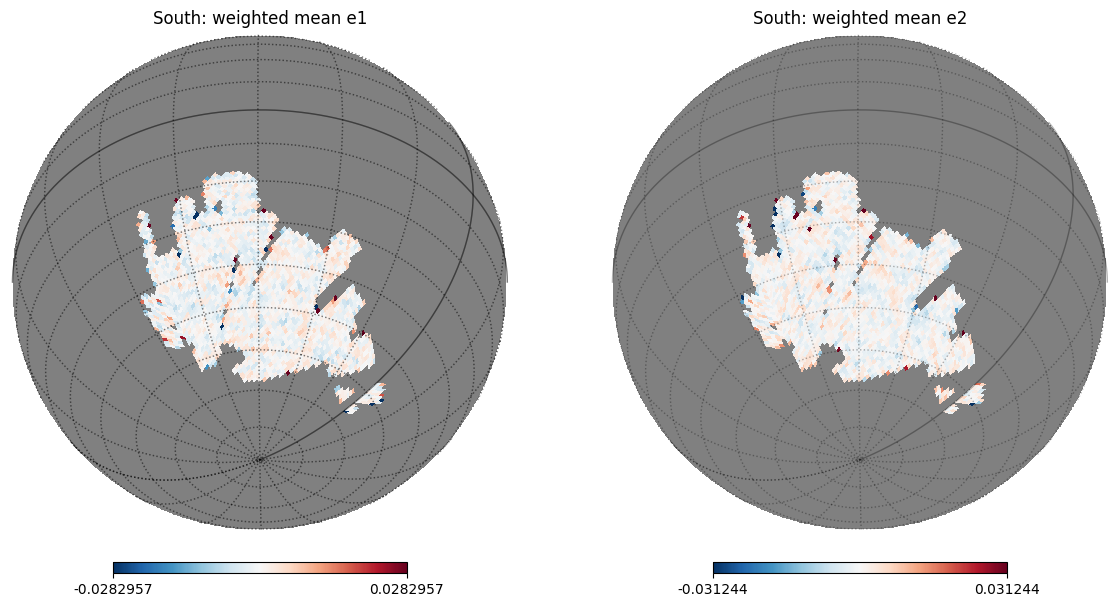

North e1: weighted mean over field -9.10e-05, pixel std 1.66e-02


North e2: weighted mean over field -8.30e-05, pixel std 1.37e-02


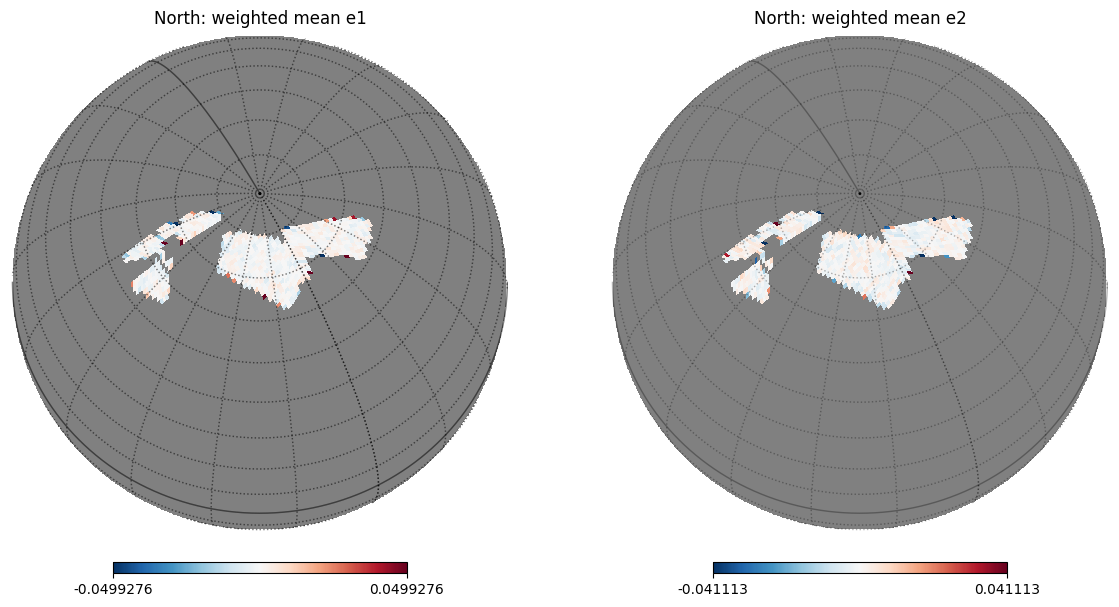

In [8]:
for name, sel in fields64.items():
    fig = plt.figure(figsize=(12, 6))
    for i, comp in enumerate(['e1', 'e2']):
        swe = hp.ud_grade(maps[f'sw{comp}'], nside_qml, power=-2)
        mean_e = np.where(sel, swe / np.where(sel, sw64, 1), hp.UNSEEN)
        lim = 3 * np.std(mean_e[sel])
        print(f'{name} {comp}: weighted mean over field {np.sum(swe[sel]) / np.sum(sw64[sel]):+.2e}, '
              f'pixel std {np.std(mean_e[sel]):.2e}')
        field_view(mean_e, sel, nside_qml, sub=(1, 2, i + 1), fig=fig.number, min=-lim, max=lim, cmap='RdBu_r',
                   title=f'{name}: weighted mean {comp}')
    plt.savefig(f'{fig_dir}/metacal_mean_shear_N64_{name.lower()}.png', dpi=150, bbox_inches='tight')
    plt.show()